# Importance des variables : pourquoi la mesure standard est fausse, et comment la réparer

**Ce notebook ne suppose aucune connaissance préalable.** On part de zéro : ce qu'est un arbre de
décision, ce qu'il mesure, pourquoi sa mesure d'importance est biaisée, et les deux remèdes que ce
projet combine.

Chaque idée est montrée, pas seulement décrite : tout le code tourne, toutes les figures sont
produites par les cellules.

> **Pour exécuter** : lancez depuis la racine du dépôt (`jupyter lab notebooks/cours.ipynb`).
> Dépendances : `numpy`, `scipy`, `scikit-learn`, `pandas`, `matplotlib`.

---

## Plan

| | |
|---|---|
| 1 | La question qu'on se pose |
| 2 | Un arbre de décision, construit pas à pas |
| 3 | L'impureté : la seule chose que l'arbre optimise |
| 4 | Le MDI, mesure d'importance standard |
| 5 | **Le bug** : de l'importance venue de nulle part |
| 6 | Pourquoi : une identité en trois lignes |
| 7 | Le second biais : juger sur sa propre copie |
| 8 | Remède 1 : mesurer sur des données non vues |
| 9 | Remède 2 : élaguer l'arbre |
| 10 | Comment on sait qui a raison (et les scénarios disponibles) |
| 11 | Le plan d'expérience |
| 12 | Ce qu'on a trouvé |

In [178]:
import sys, warnings
from pathlib import Path

# marche qu'on lance depuis la racine du depot ou depuis notebooks/
racine = Path.cwd()
while not (racine / "src" / "simulate.py").exists() and racine != racine.parent:
    racine = racine.parent
sys.path.insert(0, str(racine / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# palette unique pour tout le notebook
INK, SOFT, GRID = "#16191f", "#4e545f", "#dfe2e9"
BLEU, ORANGE, VERT, PRUNE = "#2a78d6", "#eb6834", "#1baf7a", "#3a4a86"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": SOFT, "text.color": INK,
    "xtick.color": SOFT, "ytick.color": SOFT, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 110,
})
print("prêt")

prêt


---
## 1. La question qu'on se pose

Vous avez un tableau. Chaque ligne est une observation, chaque colonne une **variable**, et une
colonne à part — notée $y$ — est ce qu'on cherche à **prédire**.

Exemple : des quartiers de Californie. On connaît le revenu médian, l'âge des maisons, le nombre de
pièces… et on veut prédire le **prix médian** du quartier.

| quartier | revenu | âge | pièces | → | **prix** |
|---|---|---|---|---|---|
| A | 1,5 | 40 | 4,2 | | **80 k\$** |
| B | 6,0 | 20 | 7,1 | | **350 k\$** |

Une fois qu'un modèle prédit correctement, une seconde question arrive, souvent plus intéressante
que la prédiction elle-même :

> **Quelles variables comptent vraiment ?**

C'est l'*importance des variables*. Elle sert à comprendre un phénomène, à éliminer des mesures
coûteuses et inutiles, ou à vérifier qu'un modèle ne s'appuie pas sur n'importe quoi.

Ce notebook montre que la mesure la plus utilisée pour ça est **fausse**, de deux manières
indépendantes — et ce qu'on peut y faire.

---
## 2. Un arbre de décision, construit pas à pas

Un arbre pose des questions binaires sur les variables et découpe les données en groupes.

Fabriquons un jeu minuscule : le prix dépend du revenu, et **rien d'autre**.

In [179]:
revenu = np.array([1.5, 1.8, 2.0, 6.0, 6.5, 7.0])
age    = np.array([40, 35, 18, 20, 25, 15], dtype=float)   # sans rapport avec le prix
prix   = np.array([80, 95, 110, 350, 380, 400], dtype=float)

print(f"{'quartier':>9} {'revenu':>7} {'age':>5} {'prix':>6}")
for q, r_, a_, p_ in zip("ABCDEF", revenu, age, prix):
    print(f"{q:>9} {r_:>7.1f} {a_:>5.0f} {p_:>6.0f}")
print(f"\nmoyenne des prix : {prix.mean():.0f} k$")

 quartier  revenu   age   prix
        A     1.5    40     80
        B     1.8    35     95
        C     2.0    18    110
        D     6.0    20    350
        E     6.5    25    380
        F     7.0    15    400

moyenne des prix : 236 k$


L'arbre cherche **une question** qui sépare au mieux les prix. Supposons pour l'instant que
« revenu ≤ 4 ? » est cette question (on **prouvera** que c'est le bon choix dans la partie 3) —
voyons ce que donne cette coupure, moyenne par moyenne.

In [180]:
# les moyennes sont calculees ici, pas inventees : c'est la preuve que le dessin
# ci-dessous correspond vraiment aux 6 chiffres du tableau precedent
m_tout    = prix.mean()
m_gauche  = prix[:3].mean()   # A, B, C : revenu <= 4
m_droite  = prix[3:].mean()   # D, E, F : revenu >  4
print(f"moyenne globale      : {m_tout:.0f} k$")
print(f"moyenne revenu <= 4  : {m_gauche:.0f} k$  (A, B, C)")
print(f"moyenne revenu >  4  : {m_droite:.0f} k$  (D, E, F)")

moyenne globale      : 236 k$
moyenne revenu <= 4  : 95 k$  (A, B, C)
moyenne revenu >  4  : 377 k$  (D, E, F)


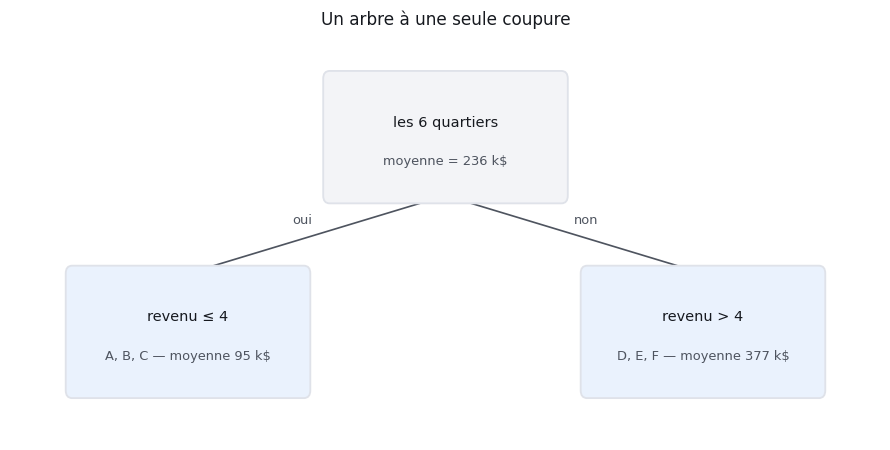

In [181]:
fig, ax = plt.subplots(figsize=(8.2, 4.2))

def boite(x, y, titre, detail, couleur):
    ax.add_patch(FancyBboxPatch((x - .72, y - .30), 1.44, .60,
                 boxstyle="round,pad=0.04", fc=couleur, ec=GRID, lw=1.2, zorder=3))
    ax.text(x, y + .08, titre, ha="center", va="center", fontsize=9.5, color=INK, zorder=4)
    ax.text(x, y - .12, detail, ha="center", va="center", fontsize=8.5, color=SOFT, zorder=4)

boite(0, 1.0, "les 6 quartiers", f"moyenne = {m_tout:.0f} k$", "#f3f4f7")
boite(-1.6, 0, "revenu ≤ 4", f"A, B, C — moyenne {m_gauche:.0f} k$", "#eaf2fd")
boite( 1.6, 0, "revenu > 4", f"D, E, F — moyenne {m_droite:.0f} k$", "#eaf2fd")
for dx in (-1.6, 1.6):
    ax.plot([0, dx], [0.70, 0.30], color=SOFT, lw=1.1, zorder=1)
ax.text(-0.95, .56, "oui", fontsize=8.5, color=SOFT)
ax.text( 0.80, .56, "non", fontsize=8.5, color=SOFT)
ax.set_xlim(-2.7, 2.7); ax.set_ylim(-.55, 1.5); ax.axis("off")
ax.set_title("Un arbre à une seule coupure", fontsize=11, color=INK, pad=10)
plt.tight_layout(); plt.show()

**Le vocabulaire, une fois pour toutes :**

- un **nœud** est un groupe de lignes ; la **racine** contient tout le monde ;
- une **coupure** envoie chaque ligne à gauche ou à droite selon une question ;
- une **feuille** est un nœud qu'on ne coupe plus ;
- pour **prédire**, on fait descendre la nouvelle ligne et on répond **la moyenne de sa feuille**.

Un nouveau quartier avec un revenu de 1,9 part à gauche → prédiction = 95 k\$.

Le point essentiel : **un nœud contient des lignes, pas des variables.**

---
## 3. L'impureté : la seule chose que l'arbre optimise

Comment l'arbre a-t-il *su* que « revenu ≤ 4 » était une bonne question ?

Il mesure à quel point les prix sont **mélangés** dans un groupe. Cette mesure s'appelle
l'**impureté**, et en régression c'est simplement la **variance** :

$$H(\text{nœud}) = \text{moyenne des } (y_i - \bar{y}_{\text{nœud}})^2$$

- prix tous proches → impureté **faible** (groupe homogène) ;
- prix dispersés → impureté **élevée** ;
- tous identiques → impureté **nulle**, le nœud est dit *pur*.

In [182]:
def impurete(v):
    return float(np.mean((v - v.mean())**2))

gauche, droite = prix[:3], prix[3:]
H_avant = impurete(prix)
H_apres = (len(gauche)/len(prix))*impurete(gauche) + (len(droite)/len(prix))*impurete(droite)

print(f"impureté AVANT la coupure : {H_avant:8.1f}")
print(f"impureté APRÈS (pondérée) : {H_apres:8.1f}") # pondéré par nb de points dans chaque noeud
print(f"{'':>26} {'-'*8}")
print(f"baisse d'impureté         : {H_avant - H_apres:8.1f}   <- le gain de cette coupure") #ce que sklearn optimise en interne

impureté AVANT la coupure :  20120.1
impureté APRÈS (pondérée) :    286.1
                           --------
baisse d'impureté         :  19834.0   <- le gain de cette coupure


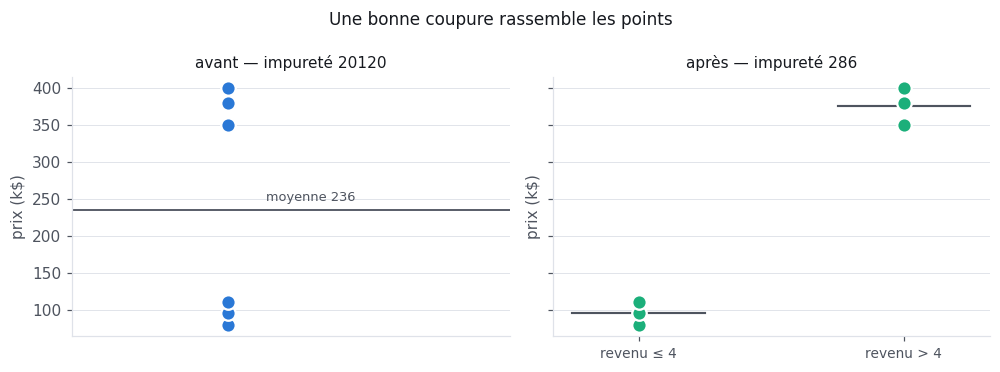

In [183]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4), sharey=True)

axes[0].scatter(np.zeros(6), prix, s=90, color=BLEU, zorder=3, edgecolor="white", lw=1.5)
axes[0].axhline(prix.mean(), color=SOFT, lw=1.2, ls="-")
axes[0].text(.12, prix.mean()+12, f"moyenne {prix.mean():.0f}", fontsize=8.5, color=SOFT)
axes[0].set_title(f"avant — impureté {H_avant:.0f}", fontsize=10)
axes[0].set_xlim(-.5, .9); axes[0].set_xticks([])

for i, (grp, lab) in enumerate([(gauche, "revenu ≤ 4"), (droite, "revenu > 4")]):
    axes[1].scatter(np.full(len(grp), i), grp, s=90, color=VERT, zorder=3,
                    edgecolor="white", lw=1.5)
    axes[1].plot([i-.25, i+.25], [grp.mean()]*2, color=SOFT, lw=1.4)
axes[1].set_title(f"après — impureté {H_apres:.0f}", fontsize=10)
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["revenu ≤ 4", "revenu > 4"], fontsize=9)

for a in axes:
    a.grid(axis="y"); a.set_ylabel("prix (k$)")
fig.suptitle("Une bonne coupure rassemble les points", fontsize=11, color=INK)
plt.tight_layout(); plt.show()

**L'algorithme complet tient en une phrase :** essayer toutes les variables et tous les seuils,
garder la coupure qui fait le plus baisser l'impureté, puis recommencer dans chaque moitié.

Une remarque qui servira beaucoup plus loin : **une coupure ne peut jamais faire *monter*
l'impureté.** Dans le pire des cas elle ne change rien. Donc le gain est toujours ≥ 0 —
**même pour une coupure sur une variable complètement inutile.**

**Reste une question qu'on n'a pas encore posée : comment l'arbre *trouve*-t-il « revenu ≤ 4 » ?**
On ne l'a pas encore montré — jusqu'ici on a seulement vérifié que cette coupure précise est bonne,
pas qu'elle est la **meilleure** parmi toutes les possibles. Codons la recherche en entier, sans
scikit-learn.

In [184]:
def meilleure_coupure(X, y):
    '''Essaie chaque variable et chaque seuil candidat, garde le gain d'impureté le plus grand.'''
    meilleur_gain, meilleure_var, meilleur_seuil = -1.0, None, None
    for var in range(X.shape[1]):
        valeurs = np.unique(X[:, var])
        seuils = (valeurs[:-1] + valeurs[1:]) / 2        # un seuil entre chaque paire de voisins
        for s in seuils:
            gauche, droite = y[X[:, var] <= s], y[X[:, var] > s]
            apres = (gauche.size/y.size)*impurete(gauche) + (droite.size/y.size)*impurete(droite)
            gain = impurete(y) - apres
            if gain > meilleur_gain:
                meilleur_gain, meilleure_var, meilleur_seuil = gain, var, s
    return meilleure_var, meilleur_seuil, meilleur_gain

X = np.column_stack([revenu, age])
var, seuil, gain = meilleure_coupure(X, prix)
print(f"variable choisie parmi {X.shape[1]} : {['revenu', 'age'][var]}")
print(f"seuil choisi (parmi {np.unique(X[:,0]).size - 1} seuils testés sur le revenu seul) : {seuil:.2f}")
print(f"gain d'impureté : {gain:.1f}")

variable choisie parmi 2 : revenu
seuil choisi (parmi 5 seuils testés sur le revenu seul) : 4.00
gain d'impureté : 19834.0


C'est tout ce que fait `.fit()` **à un nœud donné**. Et "recommencer dans chaque moitié", c'est de
la récursion : on rappelle exactement la même fonction sur les lignes de gauche, puis sur celles de
droite, jusqu'à ce qu'un critère d'arrêt soit atteint (profondeur maximale, nœud déjà pur, trop peu
de lignes…). Codons aussi cette récursion :

In [185]:
def construire(X, y, profondeur, max_profondeur):
    '''La meme recherche, appelee recursivement : c'est tout l'algorithme de construction.'''
    if profondeur == max_profondeur or np.ptp(y) == 0:    # trop profond, ou le noeud est deja pur
        return {"feuille": True, "moyenne": float(y.mean()), "n": int(y.size)}
    var, seuil, gain = meilleure_coupure(X, y)
    if gain <= 0:                                          # aucune coupure n'apporte rien
        return {"feuille": True, "moyenne": float(y.mean()), "n": int(y.size)}
    masque = X[:, var] <= seuil
    return {
        "feuille": False, "variable": ["revenu", "age"][var], "seuil": round(seuil, 2),
        "gauche": construire(X[masque],  y[masque],  profondeur + 1, max_profondeur),
        "droite": construire(X[~masque], y[~masque], profondeur + 1, max_profondeur),
    }

import pprint
pprint.pprint(construire(X, prix, profondeur=0, max_profondeur=1))

{'droite': {'feuille': True, 'moyenne': 376.6666666666667, 'n': 3},
 'feuille': False,
 'gauche': {'feuille': True, 'moyenne': 95.0, 'n': 3},
 'seuil': 4.0,
 'variable': 'revenu'}


Un dictionnaire imbriqué, construit à la main, qui retrouve exactement la coupure « revenu ≤ 4 »
sans qu'on la lui ait jamais donnée. **C'est ça, construire un arbre.** `DecisionTreeRegressor.fit`
fait précisément cette recherche-puis-récursion — en Cython, donc des centaines de fois plus vite,
avec des critères d'arrêt plus riches (`min_samples_leaf`, `ccp_alpha`…), mais le même calcul.

C'est aussi pourquoi on ne peut pas afficher son code avec `inspect.getsource`, comme on l'a fait
pour `src/mdi.py` et `src/prune.py` : ces deux fichiers sont écrits en Python, mais `.fit()` est du
code compilé, invisible depuis Python.

---
## 4. Le MDI, mesure d'importance standard

L'idée est naturelle : si une variable fait beaucoup baisser l'impureté, c'est qu'elle est utile.

> **MDI d'une variable** = somme des baisses d'impureté de **toutes les coupures faites sur cette
> variable**, chacune pondérée par le nombre de lignes concernées.

MDI veut dire *Mean Decrease in Impurity*. C'est la mesure que renvoie scikit-learn sous le nom
`feature_importances_`, et de très loin la plus utilisée en pratique.

Vérifions-la sur notre petit exemple, où l'on **sait** que seul le revenu compte.

In [186]:
from sklearn.tree import DecisionTreeRegressor

arbre = DecisionTreeRegressor(max_depth=1).fit(X, prix)

print(f"seuil trouvé par scikit-learn : {arbre.tree_.threshold[0]:.2f}")
print(f"seuil trouvé à la main        : {seuil:.2f}   <- la fonction meilleure_coupure de tout à l'heure\n")

imp = arbre.tree_.compute_feature_importances(normalize=False)
for nom, v in zip(["revenu", "âge   "], imp):
    print(f"  {nom} : {v:9.1f}")
print(f"\n  variance totale des prix : {impurete(prix):9.1f}")

seuil trouvé par scikit-learn : 4.00
seuil trouvé à la main        : 4.00   <- la fonction meilleure_coupure de tout à l'heure

  revenu :   19834.0
  âge    :       0.0

  variance totale des prix :   20120.1


Parfait : tout le crédit va au revenu, l'âge obtient zéro. La mesure fait exactement ce qu'on
attend.

**Sur cet exemple.** Voyons ce qui se passe quand on laisse l'arbre grandir.

---
## 5. Le bug : de l'importance venue de nulle part

Voici l'expérience décisive. On fabrique des données où **rien n'a de rapport avec rien** :

- $y$ est du bruit pur ;
- les 5 variables sont du bruit pur ;
- aucune relation, par construction.

La bonne réponse est donc : **importance nulle pour les cinq variables.**

In [187]:
rng = np.random.default_rng(0)
X_bruit = rng.normal(size=(100, 5))      # 5 variables de bruit pur
y_bruit = rng.normal(size=100)           # y sans aucun rapport

complet = DecisionTreeRegressor(random_state=0).fit(X_bruit, y_bruit)   # arbre complet
imp = complet.tree_.compute_feature_importances(normalize=False)
#à chaque nœud, scikit-learn garde en mémoire l'impureté de ce nœud (calculée sur les lignes d'entraînement tombées dedans)

print("vérité :  0.000  pour les cinq variables\n")
for j, v in enumerate(imp):
    print(f"  variable {j} : {v:.3f}")
print(f"\n  SOMME             : {imp.sum():.3f}")
print(f"  variance de y     : {y_bruit.var():.3f}   <- identique !")
print(f"  feuilles de l'arbre : {complet.get_n_leaves()}  (pour 100 points)")

vérité :  0.000  pour les cinq variables

  variable 0 : 0.170
  variable 1 : 0.168
  variable 2 : 0.086
  variable 3 : 0.097
  variable 4 : 0.304

  SOMME             : 0.824
  variance de y     : 0.824   <- identique !
  feuilles de l'arbre : 100  (pour 100 points)


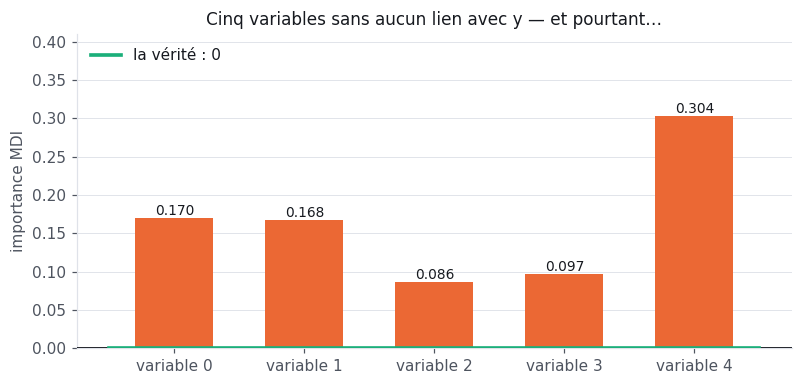

In [188]:
fig, ax = plt.subplots(figsize=(7.4, 3.6))
b = ax.bar(range(5), imp, color=ORANGE, width=.6, zorder=3)
ax.axhline(0, color=INK, lw=1.2, zorder=4)
ax.plot([-.5, 4.5], [0, 0], color=VERT, lw=2.4, zorder=5, label="la vérité : 0")
for r_, v in zip(b, imp):
    ax.text(r_.get_x()+r_.get_width()/2, v+.004, f"{v:.3f}", ha="center", fontsize=9, color=INK)
ax.set_xticks(range(5)); ax.set_xticklabels([f"variable {j}" for j in range(5)])
ax.set_ylabel("importance MDI"); ax.grid(axis="y")
ax.set_ylim(top=imp.max()*1.35)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Cinq variables sans aucun lien avec y — et pourtant…", fontsize=11, color=INK)
plt.tight_layout(); plt.show()

**Chaque variable reçoit une importance franchement positive, alors que la vérité est zéro pour
toutes.** Rien dans ces données ne prédit quoi que ce soit, et la mesure affirme le contraire.

Remarquez aussi le second chiffre : la **somme des importances vaut exactement la variance de
$y$**. Ce n'est pas une coïncidence — c'est l'explication complète du phénomène.

---
## 6. Pourquoi : une identité en trois lignes

Additionnons les MDI de **toutes** les variables. Chaque nœud interne apparaît deux fois dans la
somme : une fois en positif (comme parent), une fois en négatif (comme enfant de son propre
parent). Tout ce qui est au milieu **s'annule**, et il ne reste que les extrémités :

$$\sum_j \text{MDI}_j \;=\; \underbrace{H(\text{racine})}_{\text{variance de } y} \;-\; \underbrace{\sum_{\text{feuilles}} \frac{n_\ell}{n} H(\ell)}_{\text{erreur d'entraînement}}$$

Or un arbre qu'on laisse pousser jusqu'au bout met **un seul point par feuille**. Et la variance
d'un point tout seul vaut… **zéro** : une valeur ne s'écarte pas d'elle-même.

L'erreur d'entraînement disparaît, et il reste :

$$\sum_j \text{MDI}_j \;=\; \text{variance de } y \;=\; \underbrace{\text{signal}}_{\text{explicable}} + \underbrace{\text{bruit}}_{\textbf{inexplicable}}$$

**L'arbre distribue donc le bruit entre les variables comme si c'était de l'information.**
Dans l'exemple précédent il n'y avait *que* du bruit — d'où une importance entièrement fabriquée.

In [189]:
somme_mdi = imp.sum()
var_y     = float(np.mean((y_bruit - y_bruit.mean())**2))
err_train = float(np.mean((complet.predict(X_bruit) - y_bruit)**2))

print(f"  somme des MDI                      : {somme_mdi:.6f}")
print(f"  variance de y − erreur d'entraînement : {var_y - err_train:.6f}")
print(f"  écart                              : {abs(somme_mdi - (var_y - err_train)):.2e}")
print(f"\n  erreur d'entraînement de l'arbre complet : {err_train:.2e}  (nulle : il mémorise)")

  somme des MDI                      : 0.824408
  variance de y − erreur d'entraînement : 0.824408
  écart                              : 3.33e-16

  erreur d'entraînement de l'arbre complet : 0.00e+00  (nulle : il mémorise)


L'identité est vérifiée à la précision machine. **Ce n'est pas un défaut d'implémentation de
scikit-learn, c'est une propriété mathématique de la mesure elle-même.**

C'est le résultat central de Scornet (2023), qui en tire une consigne sans détour : *il ne faut
jamais calculer le MDI sur un arbre entièrement développé*.

---
## 7. Le second biais : juger sur sa propre copie

Il y a un deuxième problème, **indépendant du premier**.

Rappelez-vous comment une coupure est choisie : l'arbre essaie **toutes** les possibilités et garde
celle qui a l'air la meilleure **sur les données d'entraînement**. Puis le MDI mesure à quel point
cette coupure était bonne… **sur ces mêmes données**.

> C'est noter un élève sur un examen qu'il a lui-même rédigé après avoir vu le corrigé.

Le score est gonflé par construction. Et le biais frappe plus fort les variables qui offrent
**plus de coupures possibles** : une variable continue, ou catégorielle à 50 niveaux, donne plus
d'occasions de tomber par chance sur une séparation qui « marche ».

**Les deux biais sont distincts, et appellent deux remèdes différents :**

| biais | cause | remède |
|---|---|---|
| 1 | l'arbre est trop profond pour la quantité de données | **élaguer** |
| 2 | les mêmes données choisissent *et* notent | **mesurer sur des données non vues** |

---
## 8. Remède 1 : mesurer sur des données non vues

L'idée : garder l'arbre tel qu'il a été appris, mais recalculer les baisses d'impureté sur un
**jeu de validation** — des lignes mises de côté, que l'arbre n'a jamais vues.

Pourquoi ça marche : pour une variable de bruit, partir à gauche ou à droite n'a aucun rapport avec
$y$. Sur des données fraîches, les contributions positives et négatives **se compensent**, et
l'importance tombe vers 0. Elle peut même devenir **négative** — ce qui est une information utile,
et pourquoi on ne tronque jamais à zéro.

Deux mesures existent ; le projet les compare :

- **MDI-oob** (Li et al., 2019) — la même formule, évaluée ailleurs ;
- **UFI** (Zhou & Hooker, 2021) — la baisse d'entraînement **plus** celle mesurée en validation.

Utilisons l'implémentation du projet.

In [190]:
import simulate, models, mdi

scenario = simulate.scenario_s1()          # 5 vraies variables + 5 de bruit
d = scenario.n_features
verite = scenario.true_importance
bruit  = scenario.is_noise

rng = np.random.default_rng(0)
X_all, y_all = simulate.sample(scenario, 1200, rng)

# 2/3 pour construire l'arbre, 1/3 mis de côté pour mesurer
ordre = rng.permutation(1200); n_val = 400
val, tr = ordre[:n_val], ordre[n_val:]
centre = float(y_all[tr].mean())                      # on centre y (voir note plus bas)
X_tr, y_tr = X_all[tr], y_all[tr] - centre
X_val, y_val = X_all[val], y_all[val] - centre

cfg = models.ModelConfig(kind="tree")
modele = models.grow(X_tr, y_tr, cfg, seed=0)

mesures = mdi.all_measures(modele, X_val, y_val, d) #mdi_train n'utilise pas X_val et y_val car les impurité sont déjà stocké dans chaque noeud quand on a construit l'arbre

print(f"{'variable':>10} {'vérité':>8} {'mdi_train':>11} {'mdi_oob':>9} {'ufi_half':>9}")
for j in range(d):
    etiq = f"bruit {j-4}" if bruit[j] else f"signal {j+1}"
    print(f"{etiq:>10} {verite[j]:>8.3f} {mesures['mdi_train'][j]:>11.3f} "
          f"{mesures['mdi_oob'][j]:>9.3f} {mesures['ufi_half'][j]:>9.3f}")

print(f"\n{'SOMME sur le bruit (vérité = 0)':>36}")
for nom in ("mdi_train", "mdi_oob", "ufi_half"):
    print(f"{nom:>26} : {mesures[nom][bruit].sum():+8.3f}")

  variable   vérité   mdi_train   mdi_oob  ufi_half
  signal 1    0.083       0.131     0.109     0.064
  signal 2    0.500       0.443     0.435     0.443
  signal 3    0.089       0.141     0.039     0.058
  signal 4    0.250       0.309     0.319     0.285
  signal 5    0.160       0.140     0.080     0.089
   bruit 1    0.000       0.043     0.007     0.002
   bruit 2    0.000       0.017    -0.006     0.003
   bruit 3    0.000       0.044     0.002    -0.006
   bruit 4    0.000       0.042     0.002     0.006
   bruit 5    0.000       0.031    -0.005     0.001

     SOMME sur le bruit (vérité = 0)
                 mdi_train :   +0.177
                   mdi_oob :   -0.001
                  ufi_half :   +0.006


### Les trois formules

$N$ un nœud interne, $N_L$ et $N_R$ ses enfants, $v(N)$ la variable sur laquelle il coupe.
$\mu_N$ est la moyenne **d'entraînement** de $y$ dans $N$, $H(N)$ son impureté, $\omega_N$ sa part
des lignes. Les versions primées ($H'$, $\omega'$) sont les mêmes quantités comptées sur la
**validation**.

**1 · `mdi_train`** — Breiman, Friedman, Olshen & Stone, *CART* (1984) :

$$\text{MDI}_j \;=\; \sum_{N \,:\, v(N) = j} \Big[\omega_N H(N) - \omega_{N_L} H(N_L) - \omega_{N_R} H(N_R)\Big]$$

La baisse d'impureté de la partie 3, sommée sur les nœuds qui coupent sur $j$. Tout est déjà dans
l'arbre : **aucune donnée nouvelle**.

**2 · `mdi_oob`** — Li, Wang, Basu, Kumbier & Yu (2019) :

$$\text{MDI-oob}_j \;=\; \frac{1}{|\mathcal{V}|}\sum_{i \in \mathcal{V}} \;\sum_{N \,:\, v(N)=j,\; x_i \to N} \big(\mu_{\text{enfant}} - \mu_N\big)\, y_i$$

Chaque ligne de validation descend dans l'arbre ; à chaque coupure sur $j$, on multiplie l'écart
entre moyennes **d'entraînement** par son vrai $y_i$ **de validation**. Sur une vraie coupure, les
deux sont corrélés et la somme reconstruit la vraie baisse. Sur une coupure de bruit, ils sont
indépendants et la somme tombe à $0$.

> Li et al. définissent ça sur les points **out-of-bag** d'une forêt. Un arbre unique n'en a pas,
> donc $\mathcal{V}$ est ici le jeu de validation : leur formule sur d'autres données non vues.

**3 · `ufi_half`** — Zhou & Hooker (2021) :

$$\text{UFI}_j \;=\; \underbrace{\text{MDI}_j}_{\text{(a) entraînement}} \;+\; \underbrace{\sum_{N : v(N)=j} \big[\omega'_N H'(N) - \omega'_{N_L} H'(N_L) - \omega'_{N_R} H'(N_R)\big]}_{\text{(b) validation}}, \qquad \text{ufi\_half}_j = \frac{\text{UFI}_j}{2}$$

La même baisse d'impureté, calculée deux fois. **Le détail qui fait tout** : dans $H'$, les écarts
sont mesurés contre $\mu_N$, la moyenne d'**entraînement**, pas celle de validation. Les lignes de
validation sont donc notées contre une prédiction fixée à l'avance — une coupure qui ne se
reproduit pas donne une baisse **négative**.

D'où le comportement des deux termes : sur une vraie coupure (b) $\to$ (a), donc
$\text{UFI} \to 2\times$ la vraie baisse → **d'où la division par 2** ; sur une coupure de bruit
(b) $\to -$(a), et tout s'annule. Vérifié sur `S1` : le rapport (b)/(a) sur le bruit vaut
$\mathbf{-0{,}998}$.

> **La division par 2 n'est pas dans l'article.** Zhou & Hooker ne font que *classer* les
> variables, où une constante multiplicative est invisible. Nous comparons chaque chiffre à $I_j$,
> donc il faut la retirer.

#### L'étude empirique qui la justifie

Le facteur 2 sort de la théorie. On l'a vérifié en mesurant le rapport $\text{UFI}/I_j$ sur `S1`,
arbre complet, 20 répétitions, à plusieurs tailles d'échantillon :

| $n$ | $\text{UFI}/I_j$ | $\text{ufi\_half}/I_j$ |
|---|---|---|
| $1\,000$ | $1{,}54$ | $0{,}77$ |
| $3\,000$ | $1{,}68$ | $0{,}84$ |
| $20\,000$ | $1{,}89$ | $0{,}94$ |
| $60\,000$ | $\mathbf{1{,}94}$ | $\mathbf{0{,}97}$ |

Le rapport **monte vers 2** quand $n$ grandit : le facteur n'est pas postulé, il se voit. Ce qui le
retient à petit $n$, c'est que $\mu_C$ est estimée sur peu de lignes — elle décrit l'échantillon
plutôt que la population, et le terme (b) ne retrouve pas sur des lignes fraîches l'écart que (a)
croit voir.

**Et diviser reste le bon choix même quand le rapport n'est pas exactement 2.** Erreur quadratique
contre $I_j$ (arbre complet, $n = 20\,000$) : $0{,}322$ sans la division, $\mathbf{0{,}001}$ avec —
**300 fois moins**.

> **Pourquoi ne pas ajuster le diviseur au cas par cas ?** Le diviseur optimal vaut $1{,}89$ ici,
> $1{,}54$ à $n = 1\,000$. On pourrait le choisir à chaque fois… mais il se calcule **à partir de
> $I_j$, la vérité**, qui n'existe pas sur données réelles. Un diviseur ajusté sur la vérité ne
> serait pas une mesure : on validerait la méthode avec l'information qu'elle est censée retrouver.
> Le 2 vient de la théorie, c'est ce qui le rend utilisable.

**Le biais qui reste est documenté, pas caché** : `ufi_half` sous-estime $I_j$ de $23\,\%$ à
$n = 1\,000$ — la taille utilisée dans ce notebook, d'où les points verts sous la diagonale dans la
figure de la partie 10 — et de $3\,\%$ seulement à $n = 60\,000$.

### Le vrai code

Ce ne sont pas des reformulations : voici la source exacte de `src/mdi.py`, celle qui a produit les
chiffres ci-dessus.

In [191]:
import inspect

print(inspect.getsource(mdi.mdi_train))

def mdi_train(tree: TreeView, n_features: int) -> FloatArray:
    """Unnormalised classic MDI. Equals compute_feature_importances(normalize=False)."""
    nodes = np.flatnonzero(tree.feature >= 0)
    left = tree.children_left[nodes]
    right = tree.children_right[nodes]
    weight = tree.weighted_n_node_samples
    drop = (
        weight[nodes] * tree.impurity[nodes]
        - weight[left] * tree.impurity[left]
        - weight[right] * tree.impurity[right]
    )
    out = np.zeros(n_features, dtype=np.float64)
    np.add.at(out, tree.feature[nodes], drop)
    return np.asarray(out / weight[0], dtype=np.float64)



`tree.feature[nodes] >= 0` repère les nœuds internes (une feuille a `feature = -2`). `weight` est
le nombre de lignes d'entraînement par nœud, `impurity` son $H$ : `drop` est le crochet de la
formule 1, calculé pour **tous** les nœuds d'un coup. `np.add.at` l'additionne dans la case de la
variable qui a fait la coupure — c'est le $\sum_{N : v(N)=j}$.

Et la version qui répare le biais — elle ne touche plus à `tree.impurity` du tout, elle **refait
descendre** `x`, `y` de validation dans l'arbre déjà construit :

In [192]:
print(inspect.getsource(mdi.mdi_oob))

def mdi_oob(
    tree: TreeView,
    x: FloatArray,
    y: FloatArray,
    n_features: int,
    weights: FloatArray | None = None,
) -> FloatArray:
    """Mean of (mu_child - mu_parent) * y over the evaluation rows reaching each split.

    Evaluated on the training rows (with their bootstrap counts as `weights` for a
    forest tree), this reproduces mdi_train exactly.
    """
    row_weight = np.ones(x.shape[0]) if weights is None else weights.astype(np.float64)
    mean = node_means(tree)
    out = np.zeros(n_features, dtype=np.float64)
    for rows, feature, parent, child in descend(tree, x):
        contribution = row_weight[rows] * (mean[child] - mean[parent]) * y[rows]
        np.add.at(out, feature, contribution)
    return np.asarray(out / row_weight.sum(), dtype=np.float64)



`descend(tree, x)` fait avancer chaque ligne de validation d'un cran dans l'arbre (c'est la fonction
qui a servi à `predict` depuis le début). À chaque cran, `mean[child] - mean[parent]` est l'écart
entre les deux moyennes **d'entraînement**, et on le multiplie par le vrai `y` de validation — jamais
vu par l'arbre. C'est tout l'algorithme de Li et al. : rien de plus qu'une multiplication accumulée
pendant la descente.

Enfin l'UFI, qui est littéralement la somme des deux termes de la formule 3 :

In [193]:
print(inspect.getsource(mdi.off_sample_drop))
print(inspect.getsource(mdi.ufi))

def off_sample_drop(
    tree: TreeView, x: FloatArray, y: FloatArray, n_features: int
) -> FloatArray:
    """The impurity drop measured on held-out rows against the training node means.

    Algebraically identical to omega'_t H'(t) - omega'_L H'(L) - omega'_R H'(R),
    since (y - mu_parent)^2 - (y - mu_child)^2 factors into the expression below.
    """
    mean = node_means(tree)
    out = np.zeros(n_features, dtype=np.float64)
    for rows, feature, parent, child in descend(tree, x):
        gap = mean[child] - mean[parent]
        contribution = gap * (2.0 * y[rows] - mean[parent] - mean[child])
        np.add.at(out, feature, contribution)
    return np.asarray(out / x.shape[0], dtype=np.float64)

def ufi(tree: TreeView, x: FloatArray, y: FloatArray, n_features: int) -> FloatArray:
    return np.asarray(
        mdi_train(tree, n_features) + off_sample_drop(tree, x, y, n_features),
        dtype=np.float64,
    )



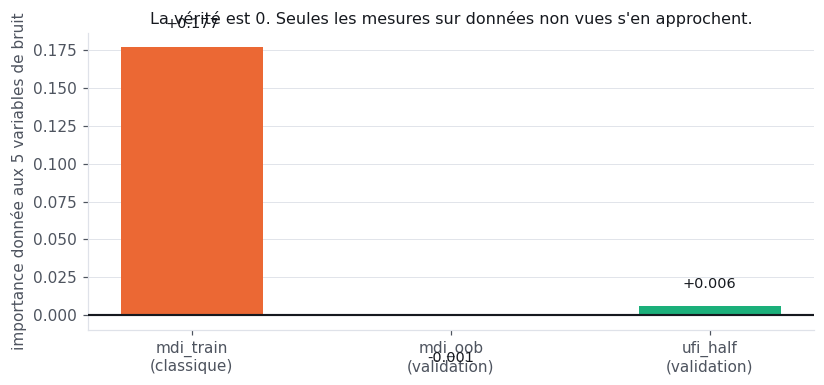

In [194]:
fig, ax = plt.subplots(figsize=(7.6, 3.6))
noms = ["mdi_train\n(classique)", "mdi_oob\n(validation)", "ufi_half\n(validation)"]
vals = [mesures[k][bruit].sum() for k in ("mdi_train", "mdi_oob", "ufi_half")]
b = ax.bar(noms, vals, color=[ORANGE, BLEU, VERT], width=.55, zorder=3)
ax.axhline(0, color=INK, lw=1.4, zorder=4)
for r_, v in zip(b, vals):
    ax.text(r_.get_x()+r_.get_width()/2, v + (.012 if v >= 0 else -.03),
            f"{v:+.3f}", ha="center", fontsize=9.5, color=INK)
ax.set_ylabel("importance donnée aux 5 variables de bruit")
ax.grid(axis="y")
ax.set_title("La vérité est 0. Seules les mesures sur données non vues s'en approchent.",
             fontsize=10.5, color=INK)
plt.tight_layout(); plt.show()

**Le remède fonctionne.** Le bruit passe d'une masse franchement positive à quelque chose
d'indiscernable de zéro.

Un dernier fait qui n'est dans aucun des deux articles, et qui découle de l'algèbre ci-dessus :
**l'UFI est insensible au décalage de $y$, le MDI-oob non.** Le MDI-oob porte un facteur $\mu_N$ qui
grandit avec la moyenne de $y$ ; l'UFI, écrit en différences de carrés, n'en a pas.

**Ce que « décaler $y$ » veut dire.** Dans `S1`, $y$ est centré autour de 0. On simule un cas
réaliste où il ne le serait pas — des prix en k\$ — en ajoutant $236$ à **toutes** les valeurs.
C'est un changement d'**origine de l'axe**, comme passer des degrés Celsius aux Kelvin : les écarts
entre points sont identiques, seul le zéro bouge. Donc $I_j$ ne change pas, les variables de bruit
valent toujours $I_j = 0$, et **la bonne réponse reste $0$**.

Et centrer, c'est remettre ce zéro en place : soustraire la moyenne d'entraînement donne à la
racine une moyenne de $\mu_{\text{racine}} = 0$ **exactement** — quel que soit le décalage de
départ. (La racine de *validation*, elle, ne vaut pas exactement 0 : c'est un autre échantillon.
C'est ce petit résidu, multiplié par $\mu_N$, qui fait dériver le MDI-oob ; le centrage le rend
petit sans l'annuler.)

La cellule suivante le met à l'épreuve : le **contre-exemple** (sans centrage) puis l'**exemple**
(avec centrage), sur le même arbre et les mêmes données, en décalant $y$ de $0$, $+10$ puis $+236$.

In [195]:
# CONTRE-EXEMPLE puis EXEMPLE. Rien ne change dans le probleme : on ajoute une
# constante a y, ce qui ne deplace aucune information. Seul le centrage differe.
print(f"{'décalage de y':>14} {'mdi_oob':>10} {'ufi_half':>10}   {'verdict':>8}")
print("-" * 50)
print("  CONTRE-EXEMPLE : y laissé tel quel (non centré)")
for dec in (0.0, 10.0, 236.0):
    yy = y_all + dec
    mauvais = models.grow(X_all[tr], yy[tr], cfg, seed=0)          # pas de centrage
    a = mdi.model_mdi_oob(mauvais,   X_all[val], yy[val], d)[bruit].sum()
    b = mdi.model_ufi_half(mauvais,  X_all[val], yy[val], d)[bruit].sum()
    verdict = "ok" if abs(a) < 0.1 else "CASSÉ"
    print(f"{dec:>14.0f} {a:>+10.3f} {b:>+10.3f}   {verdict:>8}")

print("\n  EXEMPLE : y centré par la moyenne d'ENTRAÎNEMENT")
for dec in (0.0, 10.0, 236.0):
    yy = y_all + dec
    c_tr = float(yy[tr].mean())                                    # la moyenne d'entrainement
    bon = models.grow(X_all[tr], yy[tr] - c_tr, cfg, seed=0)
    a = mdi.model_mdi_oob(bon,   X_all[val], yy[val] - c_tr, d)[bruit].sum()
    b = mdi.model_ufi_half(bon,  X_all[val], yy[val] - c_tr, d)[bruit].sum()
    verdict = "ok" if abs(a) < 0.1 else "CASSÉ"
    print(f"{dec:>14.0f} {a:>+10.3f} {b:>+10.3f}   {verdict:>8}")

print("\nLa vérité est 0 dans les six cas : le décalage n'ajoute aucune information.")

 décalage de y    mdi_oob   ufi_half    verdict
--------------------------------------------------
  CONTRE-EXEMPLE : y laissé tel quel (non centré)
             0     -0.017     -0.018         ok
            10     -0.596     -0.017      CASSÉ
           236    -13.769     -0.004      CASSÉ

  EXEMPLE : y centré par la moyenne d'ENTRAÎNEMENT
             0     -0.001     +0.006         ok
            10     -0.003     -0.022         ok
           236     -0.001     -0.004         ok

La vérité est 0 dans les six cas : le décalage n'ajoute aucune information.


**Ce que ça montre.** Décaler $y$ n'ajoute **aucune information** : la bonne réponse reste $0$ dans
les six cas. Sans centrage, le MDI-oob dérive quand même de trois ordres de grandeur et déclare les
variables de bruit massivement importantes. `ufi_half`, lui, ne bouge dans aucun des deux blocs —
ce qui confirme que le coupable est bien le facteur $\mu_N$ propre au MDI-oob.

> **Et pourquoi la moyenne d'entraînement ?** Parce que celle de validation est calculée sur des
> données qu'on prétend n'avoir jamais vues : s'en servir, même pour recentrer, ferait fuir de
> l'information — exactement le biais B qu'on veut éliminer.

---
## 9. Remède 2 : élaguer l'arbre

L'autre biais vient de la **profondeur**. Un arbre qui mémorise chaque point apprend le bruit.
**Élaguer**, c'est supprimer les coupures qui n'apprennent rien de réel.

Le projet utilise l'**alpha-trimming** (Surjanovic et al., 2024). À chaque nœud on se demande :
*les données justifient-elles statistiquement cette coupure ?* Le critère compare deux modèles —
une seule moyenne contre deux — et pénalise le second parce qu'il a plus de paramètres.

Un unique réglage $\alpha$ contrôle la sévérité : $\alpha = 0$ ne coupe rien, $\alpha$ grand élague
fort. Et surtout, **l'élagage se fait après la croissance** : un seul arbre construit suffit pour
toute la grille.

Ce qui le rend *adaptatif* : le gain d'une coupure grandit comme $|N|$, la pénalité seulement comme
$\log|N|$. Donc on élague **fort là où les données sont rares**, et peu là où elles sont nombreuses.

### Pourquoi c'est le cœur du projet

Les parties 1 à 8 sont du contexte. **C'est ici que se joue la question posée**, pour trois
raisons :

**1 · C'est la moitié du sujet.** La consigne de Scornet demande un MDI « sur des arbres **moins
profonds** (par exemple utilisant la dernière méthode), calculé sur un **jeu de données de
validation** ». Deux clauses, deux remèdes : la validation (partie 8) et l'élagage (ici), « la
dernière méthode » désignant l'alpha-trimming.

**2 · Rien ne garantit que ça marche.** Les deux remèdes ne coûtent pas la même chose : mesurer sur
la validation laisse l'arbre intact, alors qu'élaguer **détruit du vrai signal** — le théorème 3 de
Scornet (2023) dit que le MDI converge vers $\text{Var}(f_j(X_j))$ quand la profondeur
$k \to \infty$, donc *plus profond est mieux en théorie*. Élaguer échange un biais contre un autre,
et le solde peut être négatif.

**3 · La combinaison est la contribution.** Les deux remèdes existent séparément ; personne n'a
testé leur conjonction. Soit ils attaquent des défauts **différents** et s'additionnent, soit ils
attaquent **le même** (le bruit absorbé par la profondeur) et ce sont des **substituts**.

La figure qui suit montre qu'un $\alpha$ optimal existe pour la **prédiction**. Toute la question
est de savoir s'il est au même endroit pour l'**importance** — la partie 12 y répond.

**Le vrai code**, encore une fois — l'algorithme 1 du papier Surjanovic–Henrey–Loughin, transcrit
dans `src/prune.py` avec ses commentaires :

In [196]:
import prune

print(inspect.getsource(prune.alpha_trim))

def alpha_trim(tree: TreeView, alpha: float) -> TreeView:
    """Return a pruned copy of `tree`. alpha = 0 returns it unchanged."""
    if alpha == 0.0:
        return tree

    children_left = tree.children_left.copy()
    children_right = tree.children_right.copy()
    feature = tree.feature.copy()
    weight = tree.weighted_n_node_samples
    node_sse = weight * tree.impurity

    n_nodes = feature.size
    information = np.zeros(n_nodes, dtype=np.float64)
    subtree_sse = node_sse.copy()
    is_terminal = tree.feature < 0

    # reverse construction order: scikit-learn numbers a node before its subtree,
    # so descending index order visits every child before its parent
    for node in range(n_nodes - 1, -1, -1):
        if tree.feature[node] < 0:
            continue
        left = int(children_left[node])
        right = int(children_right[node])
        count = float(weight[node])

        parent_information = _information(count, count * tree.impurity[node],
                  

Les points qui comptent pour suivre le code :

- `for node in range(n_nodes - 1, -1, -1)` : on part des **feuilles** et on remonte — on ne peut
  décider de fusionner un nœud qu'une fois que ses deux enfants sont déjà tranchés.
- `_information(...)` calcule l'équation (4) de l'article : à variance égale, un nœud dont les
  points sont loin de la moyenne (`sum_squares` grand) a une information faible — moins
  d'évidence qu'il faut deux moyennes plutôt qu'une.
- `merge = parent_information + alpha * root_penalty <= ...` est l'inégalité (5) — la seule
  décision de tout l'algorithme : garder la coupure ou la dissoudre.
- la boucle `while stack` à la fin corrige un cas que l'article ne traite pas explicitement : un
  nœud peut survivre à cette comparaison alors que **son parent** vient d'être fusionné plus haut —
  il faut alors le détacher aussi, sinon il reste compté bien qu'inatteignable depuis la racine.

Reste à définir **« erreur de prédiction »**, affichée plus bas : pour chaque maison de validation,
l'écart entre la prédiction et le vrai prix, mis au carré (pour que les écarts positifs et négatifs
ne s'annulent pas), moyenné sur toutes les maisons. C'est le **MSE** (*mean squared error*) :

$$\text{MSE} = \text{moyenne}\big((\hat{y}_i - y_i)^2\big)$$

Plus il est petit, mieux l'arbre prédit sur des données qu'il n'a jamais vues pour grandir.

In [197]:
base = models.grow(X_tr, y_tr, cfg, seed=0, min_samples_leaf=5)
grille = (0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 2.5, 3.0)

print(f"{'alpha':>6} {'feuilles':>9}   {'erreur de prédiction':>21}")
feuilles, erreurs = [], []
for a in grille:
    m = prune.trim(base, a)
    err = float(np.mean((m.predict(X_val) - y_val)**2))
    feuilles.append(m.mean_leaves); erreurs.append(err)
    print(f"{a:>6.2f} {m.mean_leaves:>9.0f}   {err:>21.4f}")

 alpha  feuilles    erreur de prédiction
  0.00       125                  0.6404
  0.25       125                  0.6404
  0.50       114                  0.6405
  0.75        93                  0.6441
  1.00        46                  0.5805
  1.50        17                  0.5633
  2.00         5                  0.6515
  2.50         4                  0.6573
  3.00         4                  0.6573


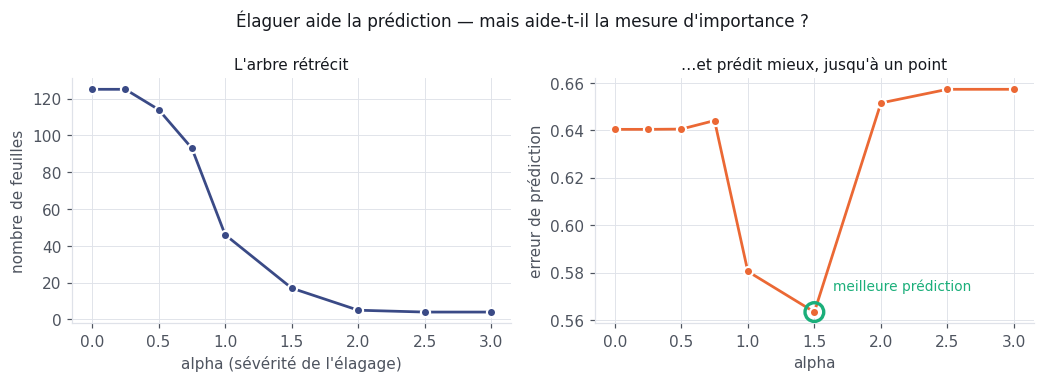

In [198]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.5))

axes[0].plot(grille, feuilles, marker="o", color=PRUNE, lw=1.8, ms=6,
             mec="white", mew=1.4, zorder=3)
axes[0].set_xlabel("alpha (sévérité de l'élagage)"); axes[0].set_ylabel("nombre de feuilles")
axes[0].set_title("L'arbre rétrécit", fontsize=10); axes[0].grid()

axes[1].plot(grille, erreurs, marker="o", color=ORANGE, lw=1.8, ms=6,
             mec="white", mew=1.4, zorder=3)
k = int(np.argmin(erreurs))
axes[1].scatter([grille[k]], [erreurs[k]], s=150, facecolor="none",
                edgecolor=VERT, lw=2.2, zorder=4)
axes[1].annotate("meilleure prédiction", (grille[k], erreurs[k]),
                 textcoords="offset points", xytext=(12, 14), fontsize=9, color=VERT)
axes[1].set_xlabel("alpha"); axes[1].set_ylabel("erreur de prédiction")
axes[1].set_title("…et prédit mieux, jusqu'à un point", fontsize=10); axes[1].grid()

fig.suptitle("Élaguer aide la prédiction — mais aide-t-il la mesure d'importance ?",
             fontsize=11, color=INK)
plt.tight_layout(); plt.show()

L'erreur descend puis remonte : il existe une quantité d'élagage optimale. **Pas assez d'élagage**
(alpha trop petit) laisse l'arbre apprendre le bruit ; **trop d'élagage** (alpha trop grand) lui
fait perdre du vrai signal.

Et c'est exactement la question du projet : **ce réglage optimal pour *prédire* est-il aussi le bon
pour *mesurer l'importance* ?** Rien ne l'impose.

---
## 10. Comment on sait qui a raison

Problème de méthode : sur des données réelles, **personne ne connaît la vraie importance**. On ne
peut donc pas dire si une mesure se trompe.

La solution : fabriquer un monde dont on connaît les règles.

$$y = f_1(x_1) + f_2(x_2) + \dots + \text{bruit}$$

On **choisit** les fonctions $f_j$, donc on peut calculer exactement la contribution de chaque
variable. C'est sa variance :

$$I_j = \text{Var}\big(f_j(x_j)\big)$$

L'intuition : *de combien cette variable fait-elle bouger $y$ ?* Une variable dont la contribution
ne bouge jamais ne distingue personne — importance nulle. Les variables de bruit ont $f_j = 0$,
donc $I_j = 0$ **exactement** : ce sont nos pièges.

Que ce soit la bonne cible est un théorème de Scornet (2023), valable quand le modèle est additif
et les variables indépendantes.

> **Pourquoi pas des données réelles ?** Parce qu'on ne pourrait rien conclure. Scornet est
> explicite : *« données simulées pour le moment : comme la véritable importance sur les jeux de
> données réelles est inconnue, il sera plus difficile de commenter les résultats. »* Le code pour
> les données réelles existe (`src/realdata.py`) mais reste en attente.

### Les scénarios disponibles

Deux familles, toutes additives à variables indépendantes — la seule situation où $I_j$ existe.

| | d'où ça vient | $d$ | signaux |
|---|---|---|---|
| `S1` | fabriqué pour ce projet : cinq formes de tailles comparables | 10 | 5 |
| `S4` | idem, mais les importances couvrent deux ordres de grandeur | 10 | 5 |
| `DS1`, `DS3`, `DS4`, `DS6`, `DS8` | **Duroux & Scornet (2016)**, section 4 | 30 à 1000 | 2 à 10 |

Les modèles Duroux–Scornet sont ceux que Scornet nous a indiqués. Ils sont plus larges et plus
parcimonieux : `DS8` a 1000 variables dont **4** portent du signal.

> **Trois des huit modèles du papier sont inutilisables ici.** Les modèles 2, 5 et 7 contiennent
> des produits ($\tilde{X}_1\tilde{X}_2$) et des indicatrices à plusieurs variables. Dans ces cas,
> $\mathrm{Var}(f_j(X_j))$ n'est la MDI de population d'**aucun** arbre — il n'y a donc pas de
> vérité contre laquelle mesurer un biais. Le code les refuse explicitement.

In [199]:
# les modeles additifs du papier de Duroux & Scornet
print(f'{"modele":>7} {"d":>6} {"signaux":>9} {"sum I_j":>9}   indices porteurs de signal')
for tag in ("DS1", "DS3", "DS4", "DS6", "DS8"):
    sc_ds = simulate.duroux(tag)
    porteurs = np.flatnonzero(~sc_ds.is_noise)
    apercu = str(porteurs.tolist()[:6]) + ("…" if porteurs.size > 6 else "")
    print(f'{tag:>7} {sc_ds.n_features:>6} {porteurs.size:>9} '
          f'{sc_ds.true_importance.sum():>9.3f}   {apercu}')

for refuse in ("DS2", "DS5", "DS7"):
    try:
        simulate.duroux(refuse)
    except ValueError as e:
        print(f'\n  {refuse} -> refusé : {e}')

 modele      d   signaux   sum I_j   indices porteurs de signal
    DS1     50         2     0.129   [0, 1]
    DS3    100         4     1.449   [0, 1, 2, 3]
    DS4    100         4     9.920   [0, 1, 2, 3]
    DS6     30        10     2.500   [0, 1, 2, 3, 4, 5]…
    DS8   1000         4     3.196   [0, 2, 4, 5]

  DS2 -> refusé : DS2 is not an additive model; pick from ['DS1', 'DS3', 'DS4', 'DS6', 'DS8']

  DS5 -> refusé : DS5 is not an additive model; pick from ['DS1', 'DS3', 'DS4', 'DS6', 'DS8']

  DS7 -> refusé : DS7 is not an additive model; pick from ['DS1', 'DS3', 'DS4', 'DS6', 'DS8']


In [200]:
print(f"{'variable':>12} {'fonction':>14} {'I_j (vérité)':>13}")
for j, c in enumerate(scenario.components):
    print(f"{('bruit' if bruit[j] else 'signal'):>7} {j+1:<4} {c.name:>14} {c.variance:>13.4f}")

explicable = verite.sum()
print(f"\n  variance explicable  sum(I_j) : {explicable:.4f}")
print(f"  variance du bruit    sigma^2  : {scenario.sigma**2:.4f}")
print(f"  variance totale de y          : {explicable + scenario.sigma**2:.4f}")
print(f"  vérifiée sur l'échantillon    : {y_all.var():.4f}")

    variable       fonction  I_j (vérité)
 signal 1            linear        0.0833
 signal 2              sine        0.5000
 signal 3         quadratic        0.0889
 signal 4              step        0.2500
 signal 5              bump        0.1600
  bruit 6             noise        0.0000
  bruit 7             noise        0.0000
  bruit 8             noise        0.0000
  bruit 9             noise        0.0000
  bruit 10            noise        0.0000

  variance explicable  sum(I_j) : 1.0822
  variance du bruit    sigma^2  : 0.2706
  variance totale de y          : 1.3528
  vérifiée sur l'échantillon    : 1.3591


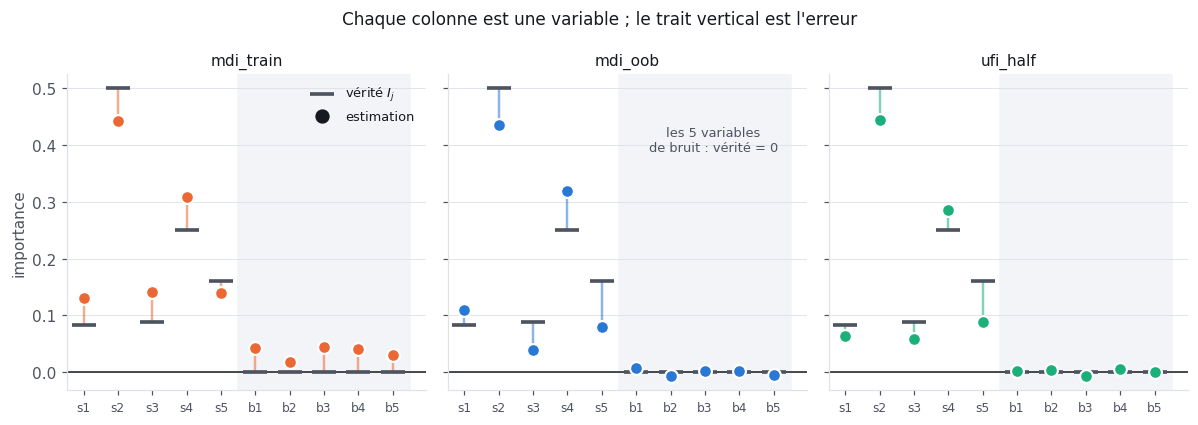

In [201]:
# Une colonne par variable. La barre grise est la VERITE, le point colore ce que
# la mesure annonce : le trait vertical entre les deux EST l'erreur.
fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.9), sharey=True)
pos = np.arange(d)
etiquettes = [f"s{j+1}" if not bruit[j] else f"b{j-4}" for j in range(d)]

for ax, (nom, coul) in zip(axes, [("mdi_train", ORANGE), ("mdi_oob", BLEU),
                                  ("ufi_half", VERT)]):
    ax.axvspan(4.5, d - 0.5, color="#f3f4f7", zorder=0)           # zone de bruit
    ax.axhline(0, color=INK, lw=1.0, zorder=2)
    est = mesures[nom]
    ax.vlines(pos, verite, est, color=coul, lw=1.6, alpha=.55, zorder=3)
    ax.scatter(pos, verite, marker="_", s=240, color=SOFT, lw=2.4, zorder=4)
    ax.scatter(pos, est, s=70, color=coul, zorder=5, edgecolor="white", lw=1.4)
    ax.set_xticks(pos); ax.set_xticklabels(etiquettes, fontsize=8)
    ax.set_title(nom, fontsize=10, color=INK)
    ax.grid(axis="y")

axes[0].set_ylabel("importance")
axes[1].text(7.25, verite.max()*.78, "les 5 variables\nde bruit : vérité = 0",
             ha="center", fontsize=8.5, color=SOFT)
axes[0].scatter([], [], marker="_", s=240, color=SOFT, lw=2.4, label="vérité $I_j$")
axes[0].scatter([], [], s=70, color=INK, label="estimation")
axes[0].legend(frameon=False, fontsize=8.5, loc="upper right")
fig.suptitle("Chaque colonne est une variable ; le trait vertical est l'erreur",
             fontsize=11, color=INK)
plt.tight_layout(); plt.show()

**Comment lire la figure.** Les 10 variables sont alignées en abscisse : `s1`…`s5` portent du
signal, `b1`…`b5` sont du bruit pur (fond grisé). Pour chacune :

- le **tiret gris** est la vérité $I_j$ — pour les cinq variables de bruit il est posé sur zéro ;
- le **point coloré** est ce que la mesure annonce ;
- le **trait vertical** qui les relie **est l'erreur**. Plus il est court, meilleure est la mesure.

Et le verdict se lit en un coup d'œil :

- **dans la zone grisée**, `mdi_train` (orange) flotte nettement au-dessus de zéro : il invente de
  l'importance. `mdi_oob` et `ufi_half` y ont des traits presque invisibles ;
- **sur les variables de signal**, c'est l'inverse : les traits orange sont courts, les bleus et
  verts plus longs et dirigés vers le bas — ils sous-estiment.

Chaque mesure est donc juste là où l'autre se trompe. C'est exactement pourquoi un seul chiffre
résumé ne suffit jamais à départager, et pourquoi l'analyse garde `noise_mass` et `signal_mass`
séparés.

---
## 11. Le plan d'expérience

Pour attribuer un écart à une cause, il faut ne faire varier **qu'une chose à la fois**. D'où sept
manières de construire l'arbre — les **bras** — toutes comparées sur les mêmes données.

| bras | l'arbre | ce qu'il sert à isoler |
|---|---|---|
| `standard` | complet, sur **toutes** les données | la pratique courante, la référence à battre |
| `full` | complet, sur l'entraînement | l'effet des données séparées, sans élagage |
| `global` | taille de feuille minimale réglée | élagage simple, non adaptatif |
| `ccp` | coût-complexité réglé | élagage classique de CART |
| `alpha0` | départ de l'alpha-trimming, **sans** élagage | le point de comparaison exact de `alpha` |
| `alpha` | alpha-trimming réglé | **la méthode étudiée** |
| `oracle` | alpha-trimming réglé **avec la vérité** | la borne : le mieux que l'élagage pourrait faire |

Deux subtilités qui font toute la rigueur du dispositif :

> **Pourquoi `alpha0` et pas `full` ?** L'alpha-trimming a besoin de partir d'un arbre dont les
> feuilles contiennent ≥ 5 points (sur des feuilles pures, son critère diverge et il ne fait rien).
> Son point de départ n'est donc pas l'arbre complet. Comparer `alpha` à `full` mélangerait
> l'élagage et la différence de profondeur de départ ; `alpha0` est le **même** arbre de départ,
> non élagué.
>
> **Pourquoi un `oracle` ?** Le réglage est choisi par validation croisée, qui optimise la
> **prédiction**. Si `alpha` ne bat pas `alpha0`, deux explications restent : l'élagage n'aide pas,
> ou le réglage était mauvais. L'oracle, qui a le droit de tricher en regardant la vérité, tranche.

---
## 12. Ce qu'on a trouvé

Montrons la question centrale directement : parcourons **tous** les niveaux d'élagage et traçons,
côte à côte, l'erreur de **prédiction** et l'erreur d'**importance**.

**L'erreur d'importance** se définit comme le MSE de la partie précédente, mais sur les $d$
importances plutôt que sur les prix : l'écart entre l'importance estimée et la vraie $I_j$, au
carré, additionné sur les $d$ variables :

$$\text{erreur d'importance} = \sum_{j=1}^{d} \big(\widehat{I_j} - I_j\big)^2$$

Rien n'impose que le même $\alpha$ minimise les deux erreurs à la fois.

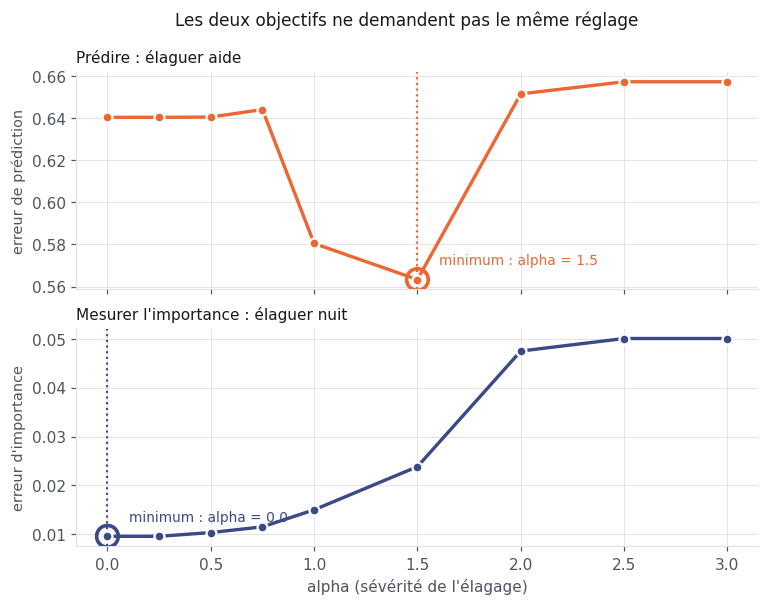

  meilleur alpha pour PRÉDIRE            : 1.5
  meilleur alpha pour MESURER L'IMPORTANCE : 0.0


In [202]:
err_importance, err_prediction = [], []
for a in grille:
    m = prune.trim(base, a)
    est = mdi.all_measures(m, X_val, y_val, d)["ufi_half"]
    err_importance.append(float(((est - verite)**2).sum()))
    err_prediction.append(float(np.mean((m.predict(X_val) - y_val)**2)))

i_pred = int(np.argmin(err_prediction))
i_imp  = int(np.argmin(err_importance))

# deux grandeurs d'unites differentes : deux panneaux empiles partageant l'axe des
# alpha, chacun a son echelle. Superposer sur deux axes verticaux ferait croire a
# des hauteurs comparables.
fig, (haut, bas) = plt.subplots(2, 1, figsize=(8.0, 5.6), sharex=True,
                                gridspec_kw={"hspace": 0.18})

for ax, serie, coul, k, titre, ylab in (
    (haut, err_prediction, ORANGE, i_pred, "Prédire : élaguer aide", "erreur de prédiction"),
    (bas,  err_importance, PRUNE,  i_imp,  "Mesurer l'importance : élaguer nuit",
     "erreur d'importance"),
):
    ax.plot(grille, serie, marker="o", color=coul, lw=2.2, ms=6.5, mec="white", mew=1.5, zorder=3)
    ax.scatter([grille[k]], [serie[k]], s=200, facecolor="none", edgecolor=coul, lw=2.4, zorder=4)
    ax.axvline(grille[k], color=coul, ls=":", lw=1.4, zorder=2)
    ax.annotate(f"minimum : alpha = {grille[k]}", (grille[k], serie[k]),
                textcoords="offset points", xytext=(14, 10), fontsize=9, color=coul)
    ax.set_ylabel(ylab, fontsize=9.5)
    ax.set_title(titre, fontsize=10, color=INK, loc="left")
    ax.grid()

bas.set_xlabel("alpha (sévérité de l'élagage)")
fig.suptitle("Les deux objectifs ne demandent pas le même réglage", fontsize=11, color=INK)
plt.tight_layout(); plt.show()

print(f"  meilleur alpha pour PRÉDIRE            : {grille[i_pred]}")
print(f"  meilleur alpha pour MESURER L'IMPORTANCE : {grille[i_imp]}")

> **Lecture.** Deux panneaux plutôt qu'une superposition : les deux grandeurs n'ont pas la même
> unité, et les mettre sur un même graphe ferait croire que leurs hauteurs se comparent. Ce qui
> compte est **où chaque courbe atteint son minimum** — et les deux pointillés ne tombent pas au
> même endroit.

### Les résultats du protocole complet

Sur l'ensemble des scénarios et des niveaux de bruit (20 répétitions, deux tailles d'échantillon) :

**1 · Le remède « données séparées » marche, et c'est le résultat le plus solide.**
L'importance attribuée à des variables prouvées inutiles chute d'un facteur allant jusqu'à 40, et
ce sur toute la gamme de bruit testée.

**2 · L'élagage n'ajoute rien par-dessus.** Mesuré sur un arbre unique (`S1`, $n = 1000$,
20 répétitions), erreur d'importance médiane :

| mesure | sans élagage | **oracle** (triche) | **alpha** (choisi par VC) |
|---|---|---|---|
| `ufi_half` | $0{,}0142$ | $0{,}0142$ — gain **0,2 %** | $0{,}0330$ — **+131 %** |
| `mdi_oob` | $0{,}0186$ | $0{,}0181$ — gain **2,6 %** | $0{,}0364$ — **+96 %** |

Deux lectures, et la seconde est la plus parlante. L'oracle — libre de choisir $\alpha$ en
regardant la vérité — élague bien un peu, mais ne gagne que $0{,}2$ à $2{,}6\,\%$ : le meilleur
élagage possible ne vaut rien. Et le niveau que la validation croisée choisit réellement **double
l'erreur**, parce qu'elle optimise la prédiction, pas l'importance.

> **Nuance de portée.** Sur les forêts, l'oracle choisissait $\alpha = 0$ dans 16 répétitions sur
> 16 — il refusait purement et simplement d'élaguer. Sur un arbre unique il élague faiblement dans
> la plupart des répétitions, pour un gain négligeable. La conclusion est la même, le mécanisme
> est un peu moins net.

**3 · Et il y a une raison mécanique.** Les deux remèdes s'attaquent à **la même chose** : le bruit
absorbé par un arbre trop profond. L'élagage le retire en raccourcissant l'arbre ; la mesure sur
données séparées le retire en refusant de créditer une coupure qui ne se reproduit pas. Appliquez
le second, il ne reste plus rien à retirer au premier — qui ne fait alors que coûter de la
résolution.

> **Ce sont des substituts, pas des partenaires.** C'est une réponse complète à la question posée,
> et elle est négative — ce que la formulation « évaluer la pertinence » invitait explicitement.

**4 · Le résultat le plus prometteur pour la suite** est celui de la figure ci-dessus : le réglage
bon pour prédire n'est pas celui qui mesure le mieux. Un critère de choix pensé pour l'importance,
et non pour la prédiction, serait une contribution à part entière.

---

### Pour aller plus loin

- `PROTOCOL.md` — le protocole complet et les définitions formelles
- `src/mdi.py` — les trois mesures, une dizaine de lignes chacune
- `src/prune.py` — l'alpha-trimming, transcrit de l'algorithme 1 de l'article
- `tests/test_all.py` — 51 tests, dont l'identité exacte qui valide tout le reste

**Les trois articles**

1. E. Scornet (2023), *Trees, forests, and impurity-based variable importance in regression* — pourquoi les arbres profonds se trompent
2. Z. Zhou & G. Hooker (2021), *Unbiased measurement of feature importance in tree-based methods* — mesurer sur des données non vues
3. N. Surjanovic, A. Henrey & T. M. Loughin (2024), *Alpha-Trimming* — l'élagage adaptatif